In [1]:
import sys
import os
from pathlib import Path

# 1.Constants

In [27]:

PROJECT_DIR=Path("/content/LungsLensAi")
SCRIPT_DIR= PROJECT_DIR / "scripts"
KAGGLE_DATASET="paultimothymooney/chest-xray-pneumonia"
DATASET_ROOT=Path("content/LungsLensAi/data/chest-xray")

SEED = 42
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
EPOCHS = 20
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
TRAIN_DIR = DATASET_ROOT / "chest_xray" / "chest_xray" / "train"
VAL_DIR = DATASET_ROOT / "chest_xray" / "chest_xray" / "val"
TEST_DIR = DATASET_ROOT / "chest_xray" / "chest_xray" / "test"
OUTPUT_DIR = PROJECT_DIR / "output"
FINAL_MODEL_PATH = OUTPUT_DIR / "model_final.keras"
CONFIG_PATH = OUTPUT_DIR / "model_config.json"
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg"
}
CHECKPOINT_PATH= OUTPUT_DIR / "best_model.keras"
TF_CHECKPOINT_PATH= OUTPUT_DIR / "best_tf_model.keras"

# 2.ENV Preparation

In [3]:
!pip install tensorflow
!pip install keras

In [4]:
sys.path.insert(0, str(SCRIPT_DIR))

In [24]:
import os
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import models,layers

from PIL import Image
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [6]:

import subprocess
def download_dataset(dataset_path, kaggle_dataset):
    if os.path.exists(dataset_path) and os.listdir(dataset_path):
        print("Dataset already exists. Skipping download.")
    else:
        print("Downloading dataset from Kaggle...")
        os.makedirs(dataset_path, exist_ok=True)

        subprocess.run(
            [
                "kaggle", "datasets", "download",
                "-d", kaggle_dataset,
                "-p", dataset_path,
                "--unzip"
            ],
            check=True
        ) 
download_dataset(DATASET_ROOT,KAGGLE_DATASET)


# 3.EDA

In [7]:
def count_images(folder):
    return sum(
        1 for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )
for split in ["train", "val", "test"]:
    split_dir = DATASET_ROOT / split

    if split_dir.exists():
        print(f"\n{split.upper()}")

        for class_name in ["NORMAL", "PNEUMONIA"]:
            class_dir = split_dir / class_name

            count = count_images(class_dir) if class_dir.exists() else 0
            print(f"  {class_name}: {count} images")

,Split,Classe,Nombre
0,train,NORMAL,1341
1,train,PNEUMONIA,3875
2,val,NORMAL,8
3,val,PNEUMONIA,8
4,test,NORMAL,234
5,test,PNEUMONIA,390


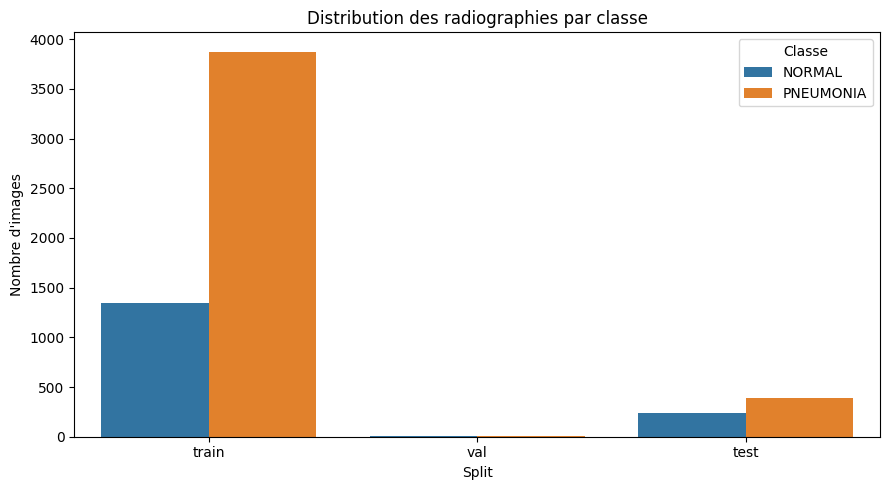

In [8]:
distribution = []

for split in ["train", "val", "test"]:
    split_dir = DATASET_ROOT / "chest_xray" / "chest_xray" / split

    if split_dir.exists():
        for class_name in ["NORMAL", "PNEUMONIA"]:
            class_dir = split_dir / class_name

            distribution.append({
                "Split": split,
                "Classe": class_name,
                "Nombre": (
                    count_images(class_dir)
                    if class_dir.exists() else 0
                )
            })

df_distribution = pd.DataFrame(distribution)
display(df_distribution)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=df_distribution,
    x="Split",
    y="Nombre",
    hue="Classe"
)
plt.title("Distribution des radiographies par classe")
plt.ylabel("Nombre d'images")
plt.tight_layout()
plt.show()

In [9]:
corrupted_images = []

for split in ["train", "val", "test"]:
    split_dir = DATASET_ROOT / split

    if not split_dir.exists():
        continue

    for path in split_dir.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(path) as img:
                img.verify()
        except Exception as exc:
            corrupted_images.append(str(path))

In [10]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    str(VAL_DIR),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(TEST_DIR),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


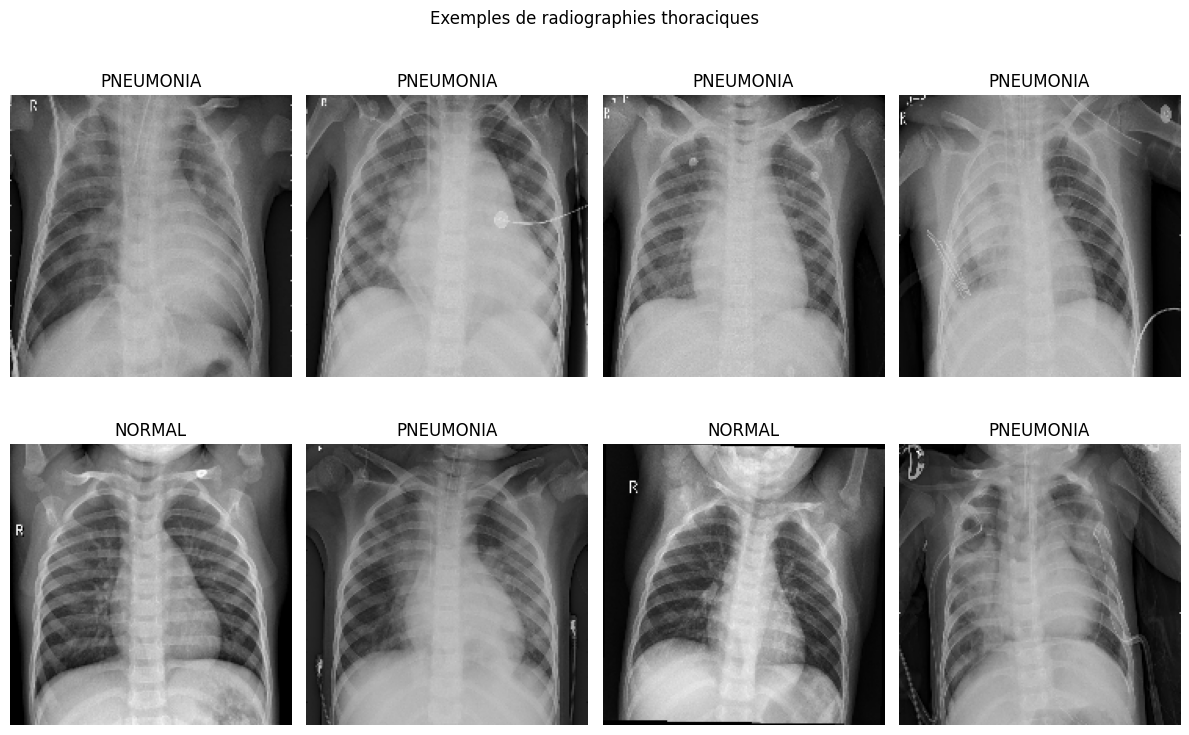

In [11]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)

    plt.imshow(
        tf.cast(images[i], tf.uint8).numpy()
    )

    class_index = int(labels[i].numpy().squeeze())

    plt.title(CLASS_NAMES[class_index])
    plt.axis("off")

plt.suptitle("Exemples de radiographies thoraciques")
plt.tight_layout()
plt.show()

In [12]:
y_train = np.concatenate([
    labels.numpy().reshape(-1).astype(int)
    for _, labels in train_ds
])

classes = np.array([0, 1])

class_counts = np.bincount(y_train, minlength=2)

print("Distribution des classes d'entraînement :")

for i, class_name in enumerate(CLASS_NAMES):
    print(f"{class_name}: {class_counts[i]} images")

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}


Distribution des classes d'entraînement :
NORMAL: 1341 images
PNEUMONIA: 3875 images


In [18]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
model = models.Sequential([
    layers.Input(shape=(None, None, 3)),
    layers.Resizing(*IMG_SIZE),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation='relu', padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
callbacks = [
     tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_PATH),
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [20]:
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

training_duration = time.time() - start_time

Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7345 - auc: 0.8157 - loss: 0.5155 - precision: 0.8910 - recall: 0.7109
Epoch 1: val_auc improved from None to 1.00000, saving model to /content/LungsLensAi/output/best_model.keras

Epoch 1: finished saving model to /content/LungsLensAi/output/best_model.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 215s 1s/step - accuracy: 0.8547 - auc: 0.9345 - loss: 0.3342 - precision: 0.9498 - recall: 0.8493 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.2058 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9477 - auc: 0.9883 - loss: 0.1351 - precision: 0.9832 - recall: 0.9448
Epoch 2: val_auc did not improve from 1.00000
163/163 ━━━━━━━━━━━━━━━━━━━━ 213s 1s/step - accuracy: 0.9500 - auc: 0.9885 - loss: 0.1324 - precision: 0.9829 - recall: 0.9492 - val_accuracy: 0.8750 - val_auc: 0.9766 - val_loss: 0.4087 - val_precision: 1.0000 - val_recall: 0.7500 - lea

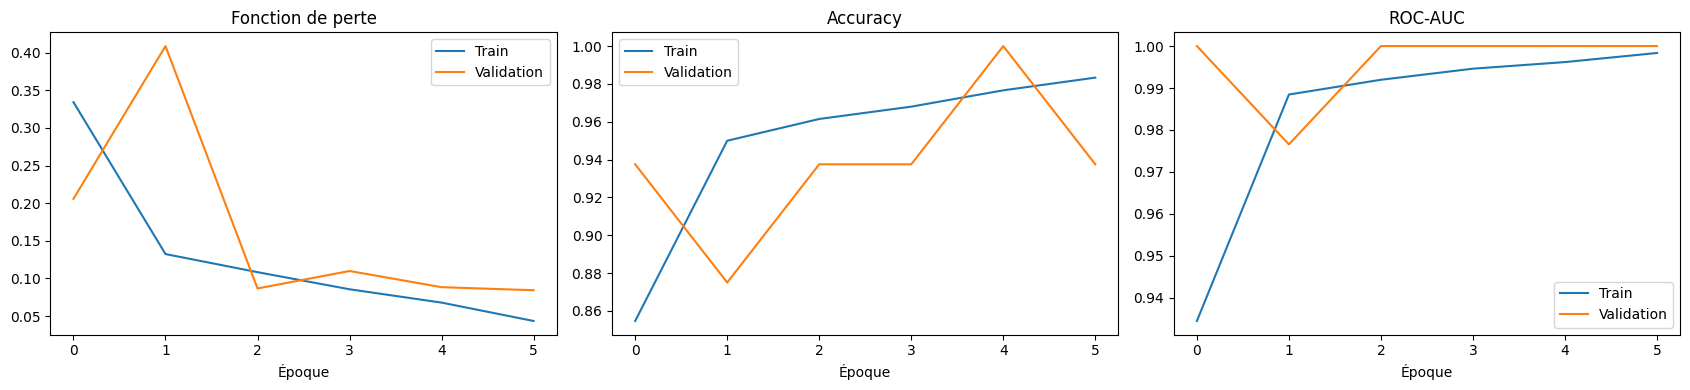

In [21]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(history_df["loss"], label="Train")
axes[0].plot(history_df["val_loss"], label="Validation")
axes[0].set_title("Fonction de perte")
axes[0].set_xlabel("Époque")
axes[0].legend()

axes[1].plot(history_df["accuracy"], label="Train")
axes[1].plot(history_df["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Époque")
axes[1].legend()

axes[2].plot(history_df["auc"], label="Train")
axes[2].plot(history_df["val_auc"], label="Validation")
axes[2].set_title("ROC-AUC")
axes[2].set_xlabel("Époque")
axes[2].legend()

plt.tight_layout()
plt.show()

In [23]:
best_model = tf.keras.models.load_model(
    str(CHECKPOINT_PATH)
)

test_results = best_model.evaluate(
    test_ds,
    return_dict=True,
    verbose=1
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 507ms/step - accuracy: 0.8205 - auc: 0.9051 - loss: 0.4986 - precision: 0.7908 - recall: 0.9692


In [26]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(128, 128, 3))
x = preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        TF_CHECKPOINT_PATH,
        monitor="val_loss",
        save_best_only=True
    )
]
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)